In [1]:
import pandas as pd
import numpy as np
from sklearn import linear_model

In [2]:
df=pd.read_csv("hiring.csv")
df

,experience,test_score(out of 10),interview_score(out of 10),salary($)
0,NaN,8.0,9,50000
1,NaN,8.0,6,45000
2,five,6.0,7,60000
3,two,10.0,10,65000
4,seven,9.0,6,70000
5,three,7.0,10,62000
6,ten,NaN,7,72000
7,eleven,7.0,8,80000


In [3]:
import math
median_testscores=math.floor(df['test_score(out of 10)'].median())
median_testscores

8

In [8]:
df['test_score(out of 10)']=df['test_score(out of 10)'].fillna(median_testscores)
df['test_score(out of 10)']

0     8.0
1     8.0
2     6.0
3    10.0
4     9.0
5     7.0
6     8.0
7     7.0
Name: test_score(out of 10), dtype: float64

In [10]:
df['experience']=df['experience'].fillna('zero')
df

,experience,test_score(out of 10),interview_score(out of 10),salary($)
0,zero,8.0,9,50000
1,zero,8.0,6,45000
2,five,6.0,7,60000
3,two,10.0,10,65000
4,seven,9.0,6,70000
5,three,7.0,10,62000
6,ten,8.0,7,72000
7,eleven,7.0,8,80000


In [11]:
%pip install word2number


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for word2number: filename=word2number-1.1-py3-none-any.whl size=5590 sha256=59e6b6eb4a60fa8d44a7d33a0ccad9e398f500461ad4fcdc615cdf0508540131
  Stored in directory: c:\users\ferdo\appdata\local\pip\cache\wheels\aa\2b\71\ede4a3c3520a8374778c16c345e0e78e25d1ffe38f4c5c1e8a
Successfully built word2number
Note: you may need to restart the kernel to use updated packages.


  DEPRECATION: Building 'word2number' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'word2number'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [14]:
from word2number import w2n
df['experience'] = (
    df['experience']
      .fillna('zero')                  # replace missing with "zero"
      .apply(lambda x: w2n.word_to_num(str(x)))  # convert word → number
)
df


,experience,test_score(out of 10),interview_score(out of 10),salary($)
0,0,8.0,9,50000
1,0,8.0,6,45000
2,5,6.0,7,60000
3,2,10.0,10,65000
4,7,9.0,6,70000
5,3,7.0,10,62000
6,10,8.0,7,72000
7,11,7.0,8,80000


In [13]:
w2n.word_to_num('zero')

0

In [16]:
reg=linear_model.LinearRegression()
reg.fit(df[['experience','test_score(out of 10)','interview_score(out of 10)']],df['salary($)'])

LinearRegression()

In [17]:
reg.coef_

array([2812.95487627, 1845.70596798, 2205.24017467])

In [18]:
reg.intercept_

np.float64(17737.26346433771)

In [21]:
reg.predict([[12,8,10]])

c:\Users\Ferdo\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([88310.77147016])

In [22]:
import matplotlib.pyplot as plt
%matplotlib inline

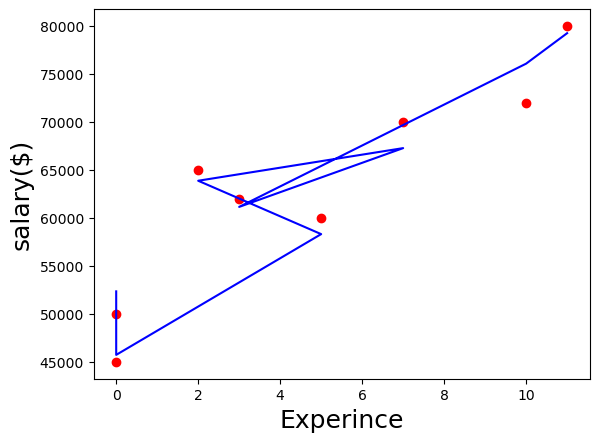

In [30]:
plt.xlabel('Experince', fontsize=18)
plt.ylabel('salary($)', fontsize=18)
plt.scatter(df['experience'], df['salary($)'],color='red')
plt.plot(df['experience'], reg.predict(df[['experience','test_score(out of 10)','interview_score(out of 10)']]), color='blue')


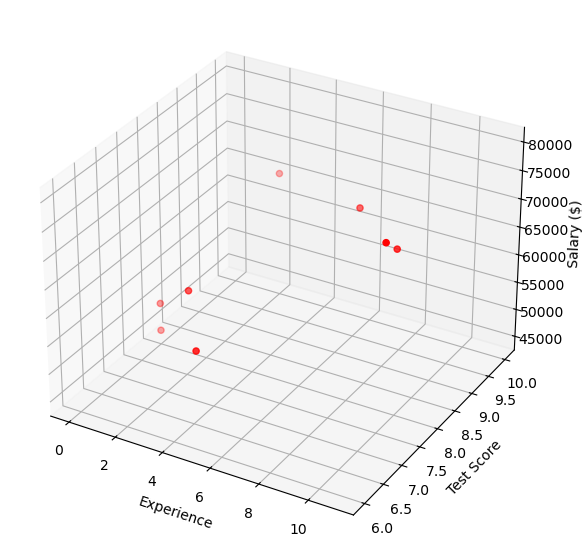

In [31]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

# Scatter points
ax.scatter(df['experience'], 
           df['test_score(out of 10)'], 
           df['salary($)'], 
           color='red', marker='o')

ax.set_xlabel("Experience")
ax.set_ylabel("Test Score")
ax.set_zlabel("Salary ($)")

plt.show()
